# Team Name — Track 2: Intelligent Financial Fraud Detection

## What this notebook does

We want to assign every transaction a **fraud probability**.

### End-to-end flow

```text
Training transactions
        ↓
Understand the data
        ↓
Handle missing values
        ↓
Create 4 behaviour-based features
        ↓
 ┌───────────────────────┐
 │ Train XGBoost model   │
 └───────────────────────┘
            +
 ┌───────────────────────┐
 │ Train CatBoost model  │
 └───────────────────────┘
        ↓
Each model outputs a fraud probability
        ↓
Final probability =
70% × XGBoost probability
+
30% × CatBoost probability
        ↓
Submission CSV
```

### Final validation result

Using **5 different stratified 5-fold CV splits**:

| Metric | 5-seed average |
|---|---:|
| Average Precision (AP) | **23.12%** |
| Precision @ 0.20 | **44.85%** |
| Recall @ 0.20 | **20.34%** |
| F1 @ 0.20 | **27.98%** |

`0.20` is used only to explain Precision / Recall / F1.  
The competition submission contains the **raw fraud probabilities**.


## 1. Setup

Before running this notebook, install the dependencies from `requirements.txt` into your Python environment. Select that environment as the notebook kernel.

We import the libraries needed for:

- data processing
- visualisation
- cross-validation
- XGBoost
- CatBoost
- saving the final model


### 1.1 Import libraries

In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier


### 1.2 Visual style

In [3]:
GREY = "#D9D9D9"
MID_GREY = "#A6A6A6"
DARK = "#2F2F2F"
GREEN = "#7A9E3A"

plt.rcParams.update({
    "figure.figsize": (7, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelcolor": DARK,
    "text.color": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK
})


## 2. Load the training data

The training set contains the answer column `fraud`:

- `0` = legitimate transaction
- `1` = fraud

The `id` column is only an identifier, so it is **not used as a model feature**.


### 2.1 Read the CSV

In [4]:
train_path = "training_dataset.csv"
train_df = pd.read_csv(train_path)

X_raw = train_df.drop(columns=["fraud", "id"])
y = train_df["fraud"]


### 2.2 Dataset overview

In [5]:
overview = pd.DataFrame({
    "Rows": [len(train_df)],
    "Input columns": [X_raw.shape[1]],
    "Fraud": [int(y.sum())],
    "Legitimate": [int((y == 0).sum())],
    "Fraud rate": [f"{y.mean() * 100:.2f}%"]
})

display(overview)


,Rows,Input columns,Fraud,Legitimate,Fraud rate
0,20000,10,353,19647,1.76%


## 3. Why fraud detection is difficult

Fraud is rare.

This means **accuracy is misleading**. A model can predict almost everything as legitimate and still appear highly accurate.

So we focus on:

- **Average Precision (AP):** how well fraud is ranked above legitimate transactions
- **Precision:** when we flag fraud, how often we are correct
- **Recall:** how much real fraud we catch
- **F1:** balance between Precision and Recall


### 3.1 Class imbalance

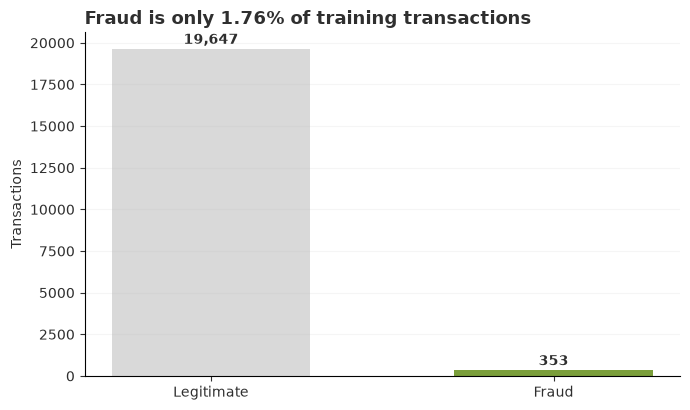

In [6]:
counts = y.value_counts().sort_index()
legit = int(counts.get(0, 0))
fraud = int(counts.get(1, 0))
fraud_rate = fraud / len(y) * 100

fig, ax = plt.subplots()

bars = ax.bar(
    ["Legitimate", "Fraud"],
    [legit, fraud],
    color=[GREY, GREEN],
    width=0.58
)

ax.set_title(
    f"Fraud is only {fraud_rate:.2f}% of training transactions",
    loc="left"
)
ax.set_ylabel("Transactions")

for bar, value in zip(bars, [legit, fraud]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + legit * 0.015,
        f"{value:,}",
        ha="center",
        fontweight="bold"
    )

ax.grid(axis="y", alpha=0.12)
plt.tight_layout()
plt.show()


## 4. What patterns do we see?

We look for patterns that help separate fraud from legitimate transactions.

These are **associations in this training dataset**, not fixed fraud rules.


### 4.1 New-device signal

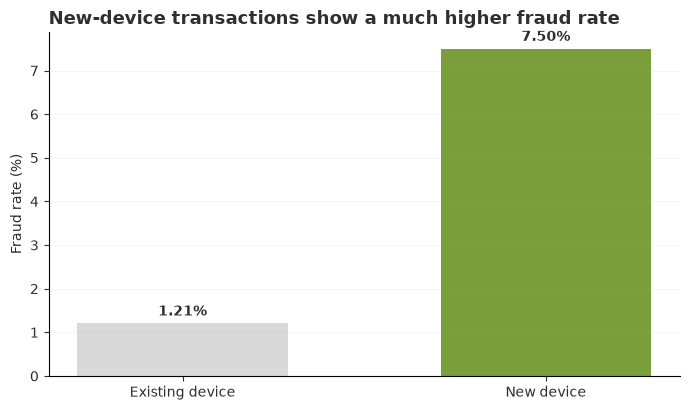

In [7]:
existing_rate = (
    train_df.loc[train_df["new_device"] == 0, "fraud"].mean() * 100
)

new_rate = (
    train_df.loc[train_df["new_device"] == 1, "fraud"].mean() * 100
)

fig, ax = plt.subplots()

bars = ax.bar(
    ["Existing device", "New device"],
    [existing_rate, new_rate],
    color=[GREY, GREEN],
    width=0.58
)

ax.set_title(
    "New-device transactions show a much higher fraud rate",
    loc="left"
)
ax.set_ylabel("Fraud rate (%)")

for bar, value in zip(bars, [existing_rate, new_rate]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.18,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.grid(axis="y", alpha=0.12)
plt.tight_layout()
plt.show()


### 4.2 Behaviour differences

In [8]:
pattern_table = pd.DataFrame({
    "Legitimate": [
        train_df.loc[y == 0, "transaction_amount"].median(),
        train_df.loc[y == 0, "spend_last_24h"].median(),
        train_df.loc[y == 0, "transactions_last_24h"].median(),
        train_df.loc[y == 0, "account_age"].median()
    ],
    "Fraud": [
        train_df.loc[y == 1, "transaction_amount"].median(),
        train_df.loc[y == 1, "spend_last_24h"].median(),
        train_df.loc[y == 1, "transactions_last_24h"].median(),
        train_df.loc[y == 1, "account_age"].median()
    ]
}, index=[
    "Transaction amount",
    "Spend in last 24h",
    "Transactions in last 24h",
    "Account age"
])

display(pattern_table.round(2))


,Legitimate,Fraud
Transaction amount,74.26,224.26
Spend in last 24h,214.51,662.82
Transactions in last 24h,4.00,5.00
Account age,796.00,335.50


### EDA takeaway

Fraud tends to show:

- larger transaction amounts
- heavier recent spending/activity
- more new-device usage
- younger accounts

However, fraud and legitimate transactions still overlap heavily.

So we do **not** use hard rules such as `new device = fraud`.  
Instead, the models combine multiple weak signals into one fraud probability.


## 5. Missing values

Some fields are incomplete.

Our handling:

- XGBoost keeps numeric missing values as `NaN`
- categorical missing values become `"Unknown"`
- CatBoost receives the same categorical missing-value label

We keep the rows because fraud is already rare and removing rows could discard useful examples.


In [9]:
missing = (
    train_df.isna().sum()
    .rename("Missing values")
    .to_frame()
    .query("`Missing values` > 0")
    .sort_values("Missing values", ascending=False)
)

display(missing)


,Missing values
transactions_last_24h,159
transactions_last_1h,142
account_age,137
spend_last_24h,132
new_device,124
transaction_channel,123
merchant_category,113
country,107


## 6. Feature engineering

We create four extra behaviour features.

The idea is simple:

```text
single signal
      ↓
may be weak

combined behaviour
      ↓
can be more informative
```

Example: a large transaction is more meaningful when it also happens on a new device.

We tested all **64 subsets** of the earlier six engineered features and kept the four that performed best and remained stable across multiple CV seeds.


| Engineered feature | Meaning |
|---|---|
| `new_device_amount` | transaction size when a new device is used |
| `new_device_txn_1h` | short-term transaction activity on a new device |
| `hour_cos` | represents time of day as a 24-hour cycle |
| `new_device_txn_24h` | daily transaction activity on a new device |


### 6.1 Create engineered features

In [10]:
def make_features(df):
    df = df.copy()

    df["new_device_amount"] = (
        df["new_device"] * df["transaction_amount"]
    )

    df["new_device_txn_1h"] = (
        df["new_device"] * df["transactions_last_1h"]
    )

    df["hour_cos"] = np.cos(
        2 * np.pi * df["transaction_hour"] / 24
    )

    df["new_device_txn_24h"] = (
        df["new_device"] * df["transactions_last_24h"]
    )

    return df


X = make_features(X_raw)


### 6.2 Define which columns each model receives

In [11]:
raw_numeric = [
    "transaction_amount",
    "transaction_hour",
    "transactions_last_24h",
    "spend_last_24h",
    "account_age",
    "new_device",
    "transactions_last_1h"
]

engineered_numeric = [
    "new_device_amount",
    "new_device_txn_1h",
    "hour_cos",
    "new_device_txn_24h"
]

categorical_cols = [
    "merchant_category",
    "country",
    "transaction_channel"
]

features = (
    raw_numeric
    + engineered_numeric
    + categorical_cols
)


## 7. Model design

We train **two separate models** on the same transactions.

```text
                    ┌→ XGBoost → P_XGB(fraud)
Transaction features│
                    └→ CatBoost → P_CAT(fraud)

Final probability
= 0.70 × P_XGB(fraud)
+ 0.30 × P_CAT(fraud)
```

The models are **not trained on each other**.  
They each make their own prediction first; we combine only their final probabilities.


### 7.1 XGBoost

XGBoost is useful for nonlinear interactions between numerical and behavioural features.

Because XGBoost does not use our categorical strings directly, we:

1. replace missing categories with `"Unknown"`
2. one-hot encode the categorical columns
3. pass the result into XGBoost


In [12]:
def build_xgb():
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            "passthrough",
            raw_numeric + engineered_numeric
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_cols
        )
    ])

    model = XGBClassifier(
        max_depth=4,
        min_child_weight=10,
        learning_rate=0.05,
        n_estimators=150,
        gamma=0,
        colsample_bytree=0.8,
        subsample=0.8,
        reg_alpha=0,
        reg_lambda=1,
        scale_pos_weight=1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        missing=np.nan
    )

    return Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])


### 7.2 CatBoost

CatBoost can use categorical values directly.

We only convert missing category values to `"Unknown"` and keep the category names as strings.


In [13]:
def prepare_catboost(df):
    df = df[features].copy()

    for col in categorical_cols:
        df[col] = (
            df[col]
            .fillna("Unknown")
            .astype(str)
        )

    return df


In [14]:
def build_catboost():
    return CatBoostClassifier(
        iterations=150,
        depth=5,
        learning_rate=0.05,
        loss_function="Logloss",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )


### 7.3 Why combine them?

XGBoost and CatBoost learn the data differently.

If they make different mistakes, averaging their probabilities can improve ranking quality.

Our tested blend is:

```text
70% XGBoost probability
+
30% CatBoost probability
```


## 8. Model comparison

We compared several model families.

The main selection metric is **Average Precision (AP)** because AP evaluates the probability ranking and does not depend on one threshold.


In [15]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest",
        "XGBoost",
        "CatBoost",
        "70/30 Blend"
    ],
    "Mean AP (%)": [
        21.548,
        20.532,
        21.013,
        22.651,
        22.474,
        23.123
    ]
})

display(model_comparison.round(2))


,Model,Mean AP (%)
0,Logistic Regression,21.55
1,Balanced Logistic Regression,20.53
2,Random Forest,21.01
3,XGBoost,22.65
4,CatBoost,22.47
5,70/30 Blend,23.12


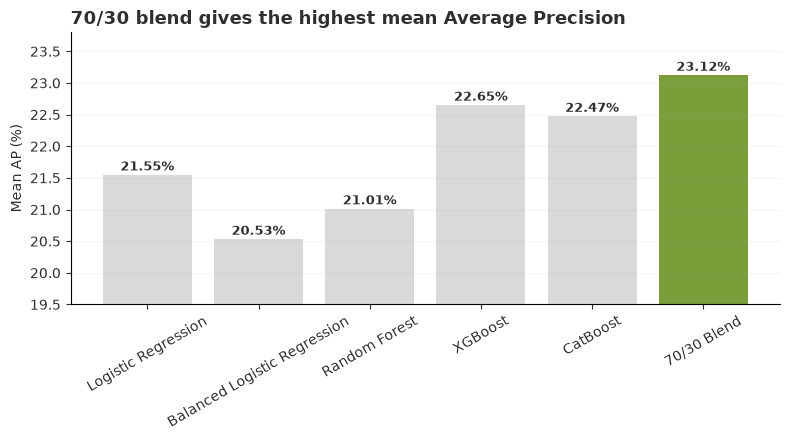

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))

colors = [GREY, GREY, GREY, GREY, GREY, GREEN]

bars = ax.bar(
    model_comparison["Model"],
    model_comparison["Mean AP (%)"],
    color=colors
)

ax.set_title(
    "70/30 blend gives the highest mean Average Precision",
    loc="left"
)
ax.set_ylabel("Mean AP (%)")
ax.set_ylim(19.5, 23.8)
ax.tick_params(axis="x", rotation=30)

for bar, value in zip(
    bars,
    model_comparison["Mean AP (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.07,
        f"{value:.2f}%",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

ax.grid(axis="y", alpha=0.12)
plt.tight_layout()
plt.show()


## 9. How we validate the final model

A single split can be lucky or unlucky.

So we use:

```text
5 CV seeds
×
5 stratified folds per seed
=
25 validation folds
```

**Stratified** means each fold keeps approximately the same fraud proportion.

CV seeds:

```text
42, 123, 2026, 7, 99
```

Important distinction:

- **CV seed** → changes how rows are split into folds
- **model seed 42** → controls randomness inside XGBoost / CatBoost training


### 9.1 Validation settings

In [17]:
seeds = [42, 123, 2026, 7, 99]
threshold = 0.20

X_cat = prepare_catboost(X)
seed_rows = []


### 9.2 Run 5-fold CV for each seed

For every fold:

1. train XGBoost on 4/5 of the data
2. train CatBoost on the same 4/5
3. predict the remaining 1/5
4. combine the two probabilities using 70/30
5. repeat until every row has been validated once


In [18]:
for seed in seeds:
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    blend_oof = np.zeros(len(y))
    fold_ap = []

    for train_idx, val_idx in cv.split(X, y):
        # Train XGBoost
        xgb = build_xgb()
        xgb.fit(
            X.iloc[train_idx][features],
            y.iloc[train_idx]
        )

        xgb_prob = xgb.predict_proba(
            X.iloc[val_idx][features]
        )[:, 1]

        # Train CatBoost
        cat = build_catboost()
        cat.fit(
            X_cat.iloc[train_idx],
            y.iloc[train_idx],
            cat_features=categorical_cols
        )

        cat_prob = cat.predict_proba(
            X_cat.iloc[val_idx]
        )[:, 1]

        # Combine their fraud probabilities
        blend_prob = (
            0.70 * xgb_prob
            + 0.30 * cat_prob
        )

        blend_oof[val_idx] = blend_prob

        fold_ap.append(
            average_precision_score(
                y.iloc[val_idx],
                blend_prob
            )
        )

    # Convert probabilities to fraud / legitimate
    # only for Precision, Recall and F1.
    pred = (blend_oof >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        pred
    ).ravel()

    seed_rows.append({
        "Seed": seed,
        "AP (%)": np.mean(fold_ap) * 100,
        "Precision (%)": precision_score(
            y, pred, zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y, pred, zero_division=0
        ) * 100,
        "F1 (%)": f1_score(
            y, pred, zero_division=0
        ) * 100,
        "Fraud caught": tp,
        "Fraud missed": fn,
        "False alarms": fp,
        "Legit correct": tn
    })


### 9.3 Results for each CV seed

In [19]:
seed_results = pd.DataFrame(seed_rows)

display(seed_results.round(2))


,Seed,AP (%),Precision (%),Recall (%),F1 (%),Fraud caught,Fraud missed,False alarms,Legit correct
0,42,22.93,44.44,20.40,27.96,72,281,90,19557
1,123,22.43,42.26,20.11,27.26,71,282,97,19550
2,2026,23.11,45.28,20.40,28.12,72,281,87,19560
3,7,22.88,44.94,20.11,27.79,71,282,87,19560
4,99,23.48,43.98,20.68,28.13,73,280,93,19554


## 10. Final validation result

We report the **average across all 5 CV seeds**, not one lucky split.


### 10.1 Average metrics

In [20]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Average Precision",
        "Precision @ 0.20",
        "Recall @ 0.20",
        "F1 @ 0.20",
        "Fraud caught",
        "Fraud missed",
        "False alarms",
        "Legitimate correct"
    ],
    "5-seed average": [
        seed_results["AP (%)"].mean(),
        seed_results["Precision (%)"].mean(),
        seed_results["Recall (%)"].mean(),
        seed_results["F1 (%)"].mean(),
        seed_results["Fraud caught"].mean(),
        seed_results["Fraud missed"].mean(),
        seed_results["False alarms"].mean(),
        seed_results["Legit correct"].mean()
    ]
})

display(final_metrics.round(2))


,Metric,5-seed average
0,Average Precision,22.97
1,Precision @ 0.20,44.18
2,Recall @ 0.20,20.34
3,F1 @ 0.20,27.85
4,Fraud caught,71.80
5,Fraud missed,281.20
6,False alarms,90.80
7,Legitimate correct,19556.20


### 10.2 What TP / FP / TN / FN mean

At threshold `0.20`:

| Outcome | Meaning |
|---|---|
| **TP — Fraud caught** | actual fraud correctly flagged |
| **FP — False alarm** | legitimate transaction wrongly flagged |
| **TN — Legitimate correct** | legitimate transaction correctly left alone |
| **FN — Fraud missed** | actual fraud not flagged |

The counts are averages across five CV seeds, so decimals are possible.


### 10.3 Metric overview

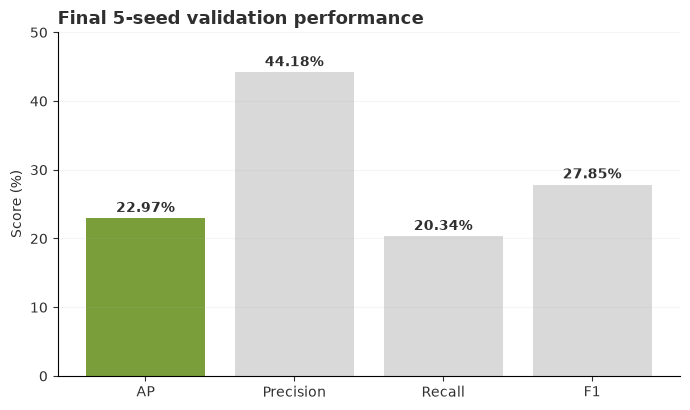

In [21]:
fig, ax = plt.subplots()

metric_plot = pd.DataFrame({
    "Metric": ["AP", "Precision", "Recall", "F1"],
    "Value": [
        seed_results["AP (%)"].mean(),
        seed_results["Precision (%)"].mean(),
        seed_results["Recall (%)"].mean(),
        seed_results["F1 (%)"].mean()
    ]
})

bars = ax.bar(
    metric_plot["Metric"],
    metric_plot["Value"],
    color=[GREEN, GREY, GREY, GREY]
)

ax.set_title("Final 5-seed validation performance", loc="left")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 50)

for bar, value in zip(
    bars,
    metric_plot["Value"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.9,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.grid(axis="y", alpha=0.12)
plt.tight_layout()
plt.show()


### 10.4 Stability across CV seeds

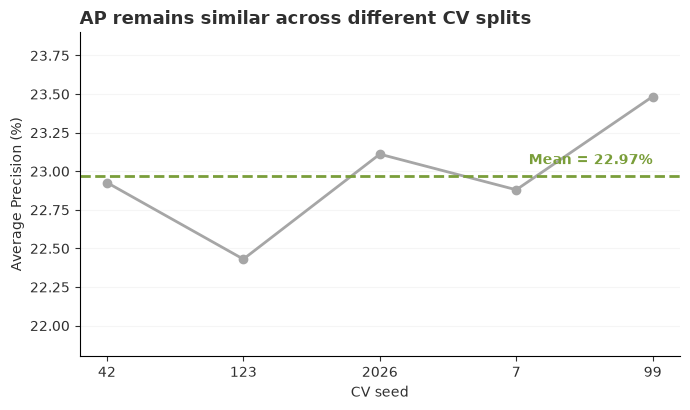

In [22]:
fig, ax = plt.subplots()

ax.plot(
    seed_results["Seed"].astype(str),
    seed_results["AP (%)"],
    marker="o",
    linewidth=2,
    color=MID_GREY
)

mean_ap = seed_results["AP (%)"].mean()

ax.axhline(
    mean_ap,
    color=GREEN,
    linestyle="--",
    linewidth=2
)

ax.text(
    4,
    mean_ap + 0.08,
    f"Mean = {mean_ap:.2f}%",
    ha="right",
    color=GREEN,
    fontweight="bold"
)

ax.set_title(
    "AP remains similar across different CV splits",
    loc="left"
)
ax.set_xlabel("CV seed")
ax.set_ylabel("Average Precision (%)")
ax.set_ylim(21.8, 23.9)
ax.grid(axis="y", alpha=0.12)

plt.tight_layout()
plt.show()


## 11. Train the final submission model

Cross-validation above was used to **evaluate and choose** the model.

Now that the model design is fixed, we train both models again using **all labelled training rows**.

```text
All labelled rows
     ↓
XGBoost final model

All labelled rows
     ↓
CatBoost final model

Both models are saved together in model.pkl
```


### 11.1 Train final XGBoost

In [23]:
xgb_model = build_xgb()

xgb_model.fit(
    X[features],
    y
)

print("XGBoost trained.")


XGBoost trained.


### 11.2 Train final CatBoost

In [24]:
X_cat_full = prepare_catboost(X)

cat_model = build_catboost()

cat_model.fit(
    X_cat_full,
    y,
    cat_features=categorical_cols
)

print("CatBoost trained.")


CatBoost trained.


### 11.3 Save both models and blend settings

In [25]:
model_bundle = {
    "xgb_model": xgb_model,
    "cat_model": cat_model,
    "xgb_weight": 0.70,
    "cat_weight": 0.30,
    "threshold": 0.20,
    "categorical_cols": categorical_cols
}

joblib.dump(
    (model_bundle, features),
    "model.pkl"
)

print("Saved: model.pkl")


Saved: model.pkl


## 12. Predict the test set

The competition test set has **no fraud labels**.

Therefore:

```text
we CAN generate fraud probabilities
we CANNOT calculate AP / Precision / Recall / F1 ourselves
```

The organisers compare our predictions with their hidden labels.


### 12.1 Load the saved model and test CSV

In [26]:
model, saved_features = joblib.load("model.pkl")

input_path = "testing_dataset.csv"

test_df = pd.read_csv(input_path)

X_test = make_features(
    test_df.drop(columns=["id"], errors="ignore")
)

print("Test transactions:", len(test_df))


Test transactions: 12000


### 12.2 XGBoost probabilities

In [27]:
xgb_prob = model["xgb_model"].predict_proba(
    X_test[saved_features]
)[:, 1]


### 12.3 CatBoost probabilities

In [28]:
X_test_cat = X_test[saved_features].copy()

for col in model["categorical_cols"]:
    X_test_cat[col] = (
        X_test_cat[col]
        .fillna("Unknown")
        .astype(str)
    )

cat_prob = model["cat_model"].predict_proba(
    X_test_cat
)[:, 1]


### 12.4 Combine the two model probabilities

In [29]:
probabilities = (
    model["xgb_weight"] * xgb_prob
    + model["cat_weight"] * cat_prob
)

print("Probabilities generated:", len(probabilities))


Probabilities generated: 12000


## 13. Save the competition submission

Team name:

**Team Name**

The CSV contains two columns:

```text
id,prediction
```

Each value is the final blended fraud probability between `0` and `1`.


In [30]:
TEAM_NAME = "Team Name"

output_file = "predictions.csv"

submission = pd.DataFrame({
    "id": test_df["id"].to_numpy(),
    "prediction": probabilities
})

submission.to_csv(
    output_file,
    index=False
)

display(submission.head())

print("Saved:", output_file)


,id,prediction
0,FR021005,0.007235
1,FR030078,0.007919
2,FR020717,0.009503
3,FR026657,0.010840
4,FR023775,0.006702


Saved: predictions.csv


### 13.1 Final safety checks

In [31]:
assert list(submission.columns) == ["id", "prediction"]
assert len(submission) == len(test_df)
assert submission["prediction"].notna().all()
assert submission["prediction"].between(0, 1).all()

print("Rows:", len(submission))
print("Missing predictions:", submission["prediction"].isna().sum())
print(
    "Probability range:",
    round(submission["prediction"].min(), 6),
    "to",
    round(submission["prediction"].max(), 6)
)
print("Final checks passed.")


Rows: 12000
Missing predictions: 0
Probability range: 0.003532 to 0.83211
Final checks passed.
